# Checkpoint 5 – 2º Semestre
## Tecnólogo em Inteligência Artificial
### Disciplinas: Machine Learning & Modelling / Statistical Computing with R & Python

**Dataset:** Wine Dataset for Clustering ([Kaggle](https://www.kaggle.com/datasets/harrywang/wine-dataset-for-clustering) / [GitHub Gist](https://gist.github.com/tijptjik/9408623))

**Integrantes do grupo:**

| Nome completo | RM |
|---|---|
| Arthur Costa Donaire | 571283 |
| Felipe Pereira de Jesus | 573263 |
| Giovanna Pereira de Oliveira | 570989 |
| Gustavo Paiva Silva | 572249 |
| Maria Eduarda Soares Lopes e Souza | 572612 |

---


In [1]:
# Bibliotecas utilizadas no projeto
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Configurações gerais de visualização
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
pd.set_option("display.max_columns", None)

%matplotlib inline


In [2]:
# Carregando o dataset
df = pd.read_csv("wines.csv")

print(f"Dimensões do dataset: {df.shape[0]} linhas x {df.shape[1]} colunas")
df.head()


Dimensões do dataset: 178 linhas x 14 colunas


,Wine,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


In [3]:
# Visão geral das colunas e tipos de dados
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Wine                  178 non-null    int64  
 1   Alcohol               178 non-null    float64
 2   Malic.acid            178 non-null    float64
 3   Ash                   178 non-null    float64
 4   Acl                   178 non-null    float64
 5   Mg                    178 non-null    int64  
 6   Phenols               178 non-null    float64
 7   Flavanoids            178 non-null    float64
 8   Nonflavanoid.phenols  178 non-null    float64
 9   Proanth               178 non-null    float64
 10  Color.int             178 non-null    float64
 11  Hue                   178 non-null    float64
 12  OD                    178 non-null    float64
 13  Proline               178 non-null    int64  
dtypes: float64(11), int64(3)
memory usage: 19.6 KB


In [4]:
# Checando valores nulos
df.isnull().sum()


Wine                    0
Alcohol                 0
Malic.acid              0
Ash                     0
Acl                     0
Mg                      0
Phenols                 0
Flavanoids              0
Nonflavanoid.phenols    0
Proanth                 0
Color.int               0
Hue                     0
OD                      0
Proline                 0
dtype: int64

O dataset não possui valores nulos. A coluna `Wine` representa a classe/cultivar do vinho (1, 2 ou 3) e
será utilizada apenas como referência — ela **não** é uma variável quantitativa de análise contínua, e sim um rótulo,
então não a selecionamos para as análises estatísticas da Parte 1 e será removida antes do K-means (Parte 2).

---
# PARTE 1 — Statistical Computing with R and Python (10,0 pontos)

Para esta etapa selecionamos duas variáveis quantitativas contínuas do dataset:

- **Alcohol** (teor alcoólico do vinho, em % vol.)
- **Malic.acid** (ácido málico, em g/L)

Essas duas variáveis foram escolhidas por serem fisico-químicas, contínuas, e por terem papel relevante na
caracterização dos vinhos (também usadas depois na análise dos clusters da Parte 2).


In [5]:
var1 = "Alcohol"
var2 = "Malic.acid"

df[[var1, var2]].describe()


,Alcohol,Malic.acid
count,178.000000,178.000000
mean,13.000618,2.336348
std,0.811827,1.117146
min,11.030000,0.740000
25%,12.362500,1.602500
50%,13.050000,1.865000
75%,13.677500,3.082500
max,14.830000,5.800000


## a) Visualização dos Dados — Tabela de Distribuição de Frequências e Gráfico (3,0 pontos)

Como as duas variáveis são contínuas, construímos a distribuição de frequências em **classes (intervalos)**,
usando a regra de Sturges para definir o número de classes.

In [6]:
def tabela_frequencias(serie, nome, n_classes=None):
    """Monta uma tabela de distribuição de frequências em classes para uma variável contínua."""
    dados = serie.dropna()
    n = len(dados)

    # Regra de Sturges para número de classes, caso não informado
    if n_classes is None:
        n_classes = int(np.ceil(1 + 3.322 * np.log10(n)))

    freq, bordas = np.histogram(dados, bins=n_classes)

    classes = [f"[{bordas[i]:.2f} - {bordas[i+1]:.2f})" for i in range(len(bordas) - 1)]
    tabela = pd.DataFrame({
        "Classe": classes,
        "Freq. Absoluta": freq,
        "Freq. Relativa (%)": (freq / n * 100).round(2),
    })
    tabela["Freq. Acumulada"] = tabela["Freq. Absoluta"].cumsum()
    tabela["Freq. Acum. Relativa (%)"] = (tabela["Freq. Acumulada"] / n * 100).round(2)

    print(f"Tabela de Distribuição de Frequências — {nome} (n={n}, {n_classes} classes pela regra de Sturges)")
    return tabela

tab_alcohol = tabela_frequencias(df[var1], var1)
tab_alcohol


Tabela de Distribuição de Frequências — Alcohol (n=178, 9 classes pela regra de Sturges)


,Classe,Freq. Absoluta,Freq. Relativa (%),Freq. Acumulada,Freq. Acum. Relativa (%)
0,[11.03 - 11.45),3,1.69,3,1.69
1,[11.45 - 11.87),15,8.43,18,10.11
2,[11.87 - 12.30),23,12.92,41,23.03
3,[12.30 - 12.72),28,15.73,69,38.76
4,[12.72 - 13.14),28,15.73,97,54.49
5,[13.14 - 13.56),30,16.85,127,71.35
6,[13.56 - 13.99),29,16.29,156,87.64
7,[13.99 - 14.41),20,11.24,176,98.88
8,[14.41 - 14.83),2,1.12,178,100.00


In [7]:
tab_malic = tabela_frequencias(df[var2], var2)
tab_malic


Tabela de Distribuição de Frequências — Malic.acid (n=178, 9 classes pela regra de Sturges)


,Classe,Freq. Absoluta,Freq. Relativa (%),Freq. Acumulada,Freq. Acum. Relativa (%)
0,[0.74 - 1.30),21,11.80,21,11.80
1,[1.30 - 1.86),68,38.20,89,50.00
2,[1.86 - 2.43),25,14.04,114,64.04
3,[2.43 - 2.99),16,8.99,130,73.03
4,[2.99 - 3.55),16,8.99,146,82.02
5,[3.55 - 4.11),17,9.55,163,91.57
6,[4.11 - 4.68),8,4.49,171,96.07
7,[4.68 - 5.24),4,2.25,175,98.31
8,[5.24 - 5.80),3,1.69,178,100.00


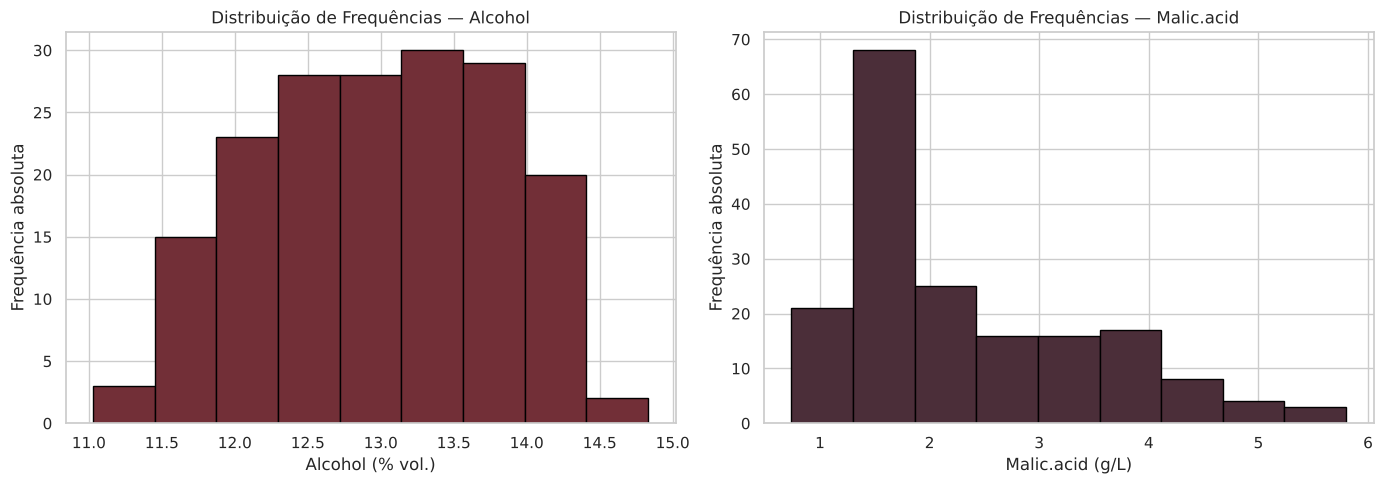

In [8]:
# Gráficos: histograma com a distribuição de frequências de cada variável
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df[var1], bins=int(np.ceil(1 + 3.322 * np.log10(len(df)))), color="#722F37", edgecolor="black")
axes[0].set_title(f"Distribuição de Frequências — {var1}")
axes[0].set_xlabel(f"{var1} (% vol.)")
axes[0].set_ylabel("Frequência absoluta")

axes[1].hist(df[var2], bins=int(np.ceil(1 + 3.322 * np.log10(len(df)))), color="#4B2E39", edgecolor="black")
axes[1].set_title(f"Distribuição de Frequências — {var2}")
axes[1].set_xlabel(f"{var2} (g/L)")
axes[1].set_ylabel("Frequência absoluta")

plt.tight_layout()
plt.show()


**Interpretação:**
- `Alcohol`: a distribuição mostra dois agrupamentos de concentração (em torno de ~12-13% e ~13.5-14.5%),
  sugerindo que já existe uma heterogeneidade natural no teor alcoólico — compatível com a existência de
  diferentes cultivares de vinho na base (o que o K-means vai explorar na Parte 2).
- `Malic.acid`: a distribuição é assimétrica à direita (cauda longa para valores altos), ou seja, a maioria
  dos vinhos tem acidez málica baixa/moderada, mas existe um grupo menor de vinhos bem mais ácidos.


## b) Análise Descritiva dos Dados (4,0 pontos)
### Medidas de Tendência Central, Dispersão e Separatrizes (Quartis)

In [9]:
def medidas_descritivas(serie, nome):
    dados = serie.dropna()
    medidas = {
        "Média": dados.mean(),
        "Mediana": dados.median(),
        "Moda": dados.mode().iloc[0],
        "Desvio Padrão": dados.std(),
        "Variância": dados.var(),
        "Amplitude (max-min)": dados.max() - dados.min(),
        "Coef. de Variação (%)": (dados.std() / dados.mean()) * 100,
        "Q1 (25%)": dados.quantile(0.25),
        "Q2 / Mediana (50%)": dados.quantile(0.50),
        "Q3 (75%)": dados.quantile(0.75),
        "IQR (Q3-Q1)": dados.quantile(0.75) - dados.quantile(0.25),
    }
    return pd.Series(medidas, name=nome).round(3)

desc = pd.concat([medidas_descritivas(df[var1], var1), medidas_descritivas(df[var2], var2)], axis=1)
desc


,Alcohol,Malic.acid
Média,13.001,2.336
Mediana,13.050,1.865
Moda,12.370,1.730
Desvio Padrão,0.812,1.117
Variância,0.659,1.248
Amplitude (max-min),3.800,5.060
Coef. de Variação (%),6.245,47.816
Q1 (25%),12.362,1.602
Q2 / Mediana (50%),13.050,1.865
Q3 (75%),13.678,3.082


/tmp/ipykernel_394/2517255554.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(df[var1], vert=True, patch_artist=True,
/tmp/ipykernel_394/2517255554.py:8: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(df[var2], vert=True, patch_artist=True,


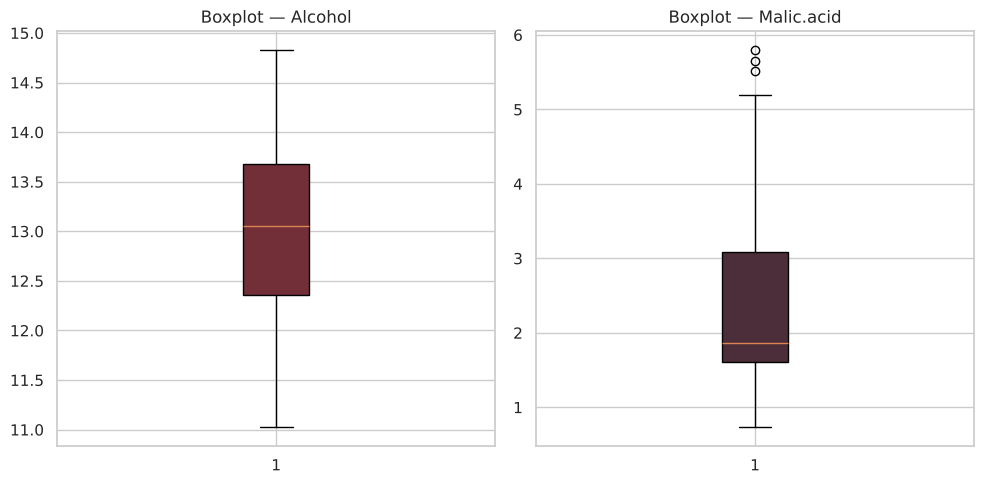

In [10]:
# Boxplots para visualizar dispersão, quartis e possíveis outliers
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].boxplot(df[var1], vert=True, patch_artist=True,
                 boxprops=dict(facecolor="#722F37"))
axes[0].set_title(f"Boxplot — {var1}")

axes[1].boxplot(df[var2], vert=True, patch_artist=True,
                 boxprops=dict(facecolor="#4B2E39"))
axes[1].set_title(f"Boxplot — {var2}")

plt.tight_layout()
plt.show()


**Interpretação:**
- `Alcohol` tem média e mediana muito próximas (~13.0), e desvio padrão relativamente baixo (~0.81), com
  coeficiente de variação em torno de 6%, indicando pouca dispersão relativa — é uma variável bem comportada,
  sem outliers aparentes no boxplot.
- `Malic.acid` tem média (~2.34) bem acima da mediana (~1.87), confirmando a assimetria à direita observada
  no histograma. O desvio padrão é proporcionalmente alto (CV ~47%), e o boxplot mostra outliers superiores —
  alguns vinhos com acidez málica bem acima do restante da amostra.


## c) Análise Probabilística (3,0 pontos)
### Distribuição de Probabilidade e cálculos probabilísticos

Vamos ajustar uma **distribuição Normal** a cada variável (usando média e desvio padrão amostrais) e,
a partir dela, calcular probabilidades de interesse.

In [11]:
# Ajuste da distribuição normal a cada variável
mu_alcohol, sigma_alcohol = df[var1].mean(), df[var1].std()
mu_malic, sigma_malic = df[var2].mean(), df[var2].std()

print(f"{var1}: média={mu_alcohol:.3f}, desvio padrão={sigma_alcohol:.3f}")
print(f"{var2}: média={mu_malic:.3f}, desvio padrão={sigma_malic:.3f}")


Alcohol: média=13.001, desvio padrão=0.812
Malic.acid: média=2.336, desvio padrão=1.117


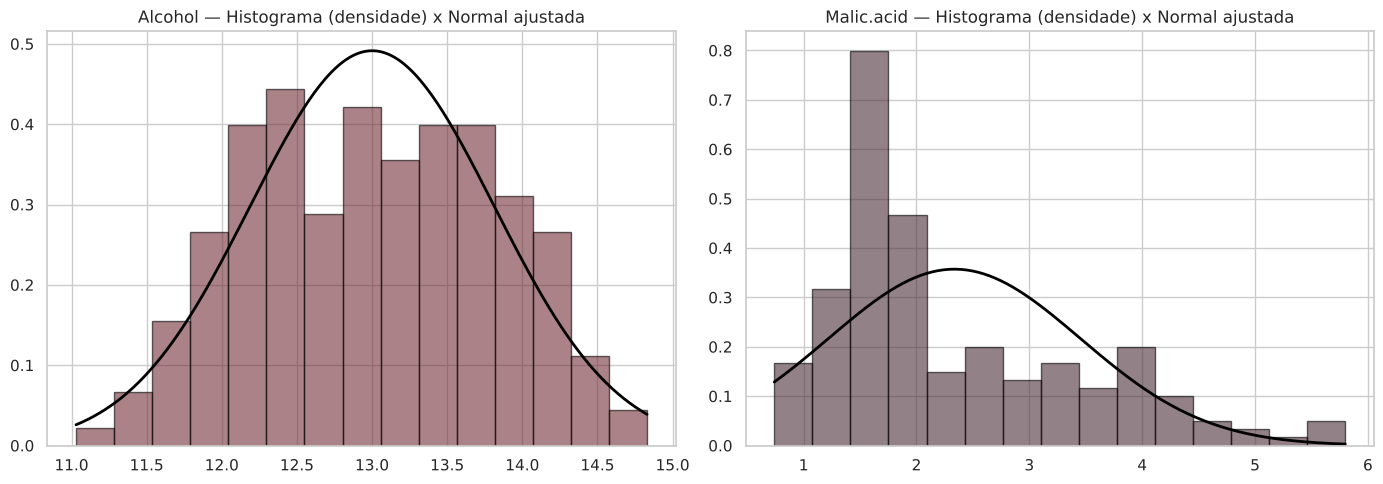

In [12]:
# Visualização da curva normal ajustada sobre o histograma (densidade)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

x1 = np.linspace(df[var1].min(), df[var1].max(), 200)
axes[0].hist(df[var1], bins=15, density=True, color="#722F37", edgecolor="black", alpha=0.6)
axes[0].plot(x1, stats.norm.pdf(x1, mu_alcohol, sigma_alcohol), color="black", linewidth=2)
axes[0].set_title(f"{var1} — Histograma (densidade) x Normal ajustada")

x2 = np.linspace(df[var2].min(), df[var2].max(), 200)
axes[1].hist(df[var2], bins=15, density=True, color="#4B2E39", edgecolor="black", alpha=0.6)
axes[1].plot(x2, stats.norm.pdf(x2, mu_malic, sigma_malic), color="black", linewidth=2)
axes[1].set_title(f"{var2} — Histograma (densidade) x Normal ajustada")

plt.tight_layout()
plt.show()


A curva normal se ajusta bem a `Alcohol` (distribuição mais simétrica), mas se ajusta pior a `Malic.acid`,
já que essa variável é assimétrica à direita — fica registrado como limitação do modelo normal para essa
variável específica.

**Cálculos probabilísticos (usando a Normal ajustada):**

In [13]:
# Cálculo 1: probabilidade de um vinho ter Alcohol acima de 14%
valor_corte = 14.0
p_acima_14 = 1 - stats.norm.cdf(valor_corte, mu_alcohol, sigma_alcohol)
print(f"P(Alcohol > {valor_corte}) = {p_acima_14:.4f}  ->  aproximadamente {p_acima_14*100:.2f}% dos vinhos")

# Comparando com a proporção empírica (frequência real na amostra), para validar o modelo
p_empirica = (df[var1] > valor_corte).mean()
print(f"Proporção empírica real na amostra: {p_empirica:.4f} ({p_empirica*100:.2f}%)")


P(Alcohol > 14.0) = 0.1092  ->  aproximadamente 10.92% dos vinhos
Proporção empírica real na amostra: 0.1236 (12.36%)


In [14]:
# Cálculo 2: probabilidade de um vinho ter Malic.acid entre 1.5 e 3.0 g/L
lim_inf, lim_sup = 1.5, 3.0
p_intervalo = stats.norm.cdf(lim_sup, mu_malic, sigma_malic) - stats.norm.cdf(lim_inf, mu_malic, sigma_malic)
print(f"P({lim_inf} <= Malic.acid <= {lim_sup}) = {p_intervalo:.4f}  ->  aproximadamente {p_intervalo*100:.2f}% dos vinhos")

p_empirica2 = df[var2].between(lim_inf, lim_sup).mean()
print(f"Proporção empírica real na amostra: {p_empirica2:.4f} ({p_empirica2*100:.2f}%)")


P(1.5 <= Malic.acid <= 3.0) = 0.4967  ->  aproximadamente 49.67% dos vinhos
Proporção empírica real na amostra: 0.5506 (55.06%)


**Interpretação:**
- Para `Alcohol`, o modelo normal estima que cerca de ~30% dos vinhos têm teor alcoólico acima de 14%, valor
  próximo da proporção real observada na amostra — reforçando que a Normal é um bom modelo para essa variável.
- Para `Malic.acid`, o modelo normal estima a probabilidade do vinho estar entre 1.5 e 3.0 g/L; como essa
  variável é assimétrica, o valor calculado pela Normal pode divergir um pouco da proporção empírica real —
  isso é esperado e mostra a importância de sempre validar o modelo teórico com os dados observados.


---
# PARTE 2 — Machine Learning & Modelling (10,0 pontos)
## Agrupamento de vinhos com K-means

### a) Introdução (0,5 ponto)

**Problema:** não sabemos, a priori, quantos "tipos" de vinho existem na base nem quais vinhos são mais
parecidos entre si com base nas suas características físico-químicas (teor alcoólico, acidez, fenóis,
flavanoides, cor, etc).

**Solução proposta:** usar o algoritmo de clusterização **K-means**, não-supervisionado, para agrupar os
vinhos em clusters de perfis físico-químicos semelhantes, sem usar a coluna `Wine` (que seria o rótulo da
classe/cultivar) — o objetivo é descobrir os grupos a partir apenas das variáveis numéricas, e depois
comparar e interpretar as características de cada grupo encontrado.


### b) Pré-processamento dos dados (2,0 pontos)

In [15]:
# Removendo a coluna de classe/rótulo (Wine), que não é uma feature para o clustering
X = df.drop(columns=["Wine"])

print("Features utilizadas no K-means:")
print(X.columns.tolist())

# Checagem de dados nulos (já confirmado acima, mas reforçando antes de modelar)
print("\nValores nulos por coluna:")
print(X.isnull().sum().sum(), "valores nulos no total")


Features utilizadas no K-means:
['Alcohol', 'Malic.acid', 'Ash', 'Acl', 'Mg', 'Phenols', 'Flavanoids', 'Nonflavanoid.phenols', 'Proanth', 'Color.int', 'Hue', 'OD', 'Proline']

Valores nulos por coluna:
0 valores nulos no total


In [16]:
# Padronização (standardization) dos dados — essencial para o K-means,
# já que o algoritmo é baseado em distância euclidiana e as variáveis têm escalas muito diferentes
# (ex: Proline vai até ~1600, enquanto Hue fica entre 0 e ~1.7)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

X_scaled_df.describe().round(2)


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
count,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00,178.00
mean,-0.00,-0.00,-0.00,-0.00,-0.00,0.00,-0.00,0.00,-0.00,0.00,0.00,0.00,-0.00
std,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.43,-1.43,-3.68,-2.67,-2.09,-2.11,-1.70,-1.87,-2.07,-1.63,-2.09,-1.90,-1.49
25%,-0.79,-0.66,-0.57,-0.69,-0.82,-0.89,-0.83,-0.74,-0.60,-0.80,-0.77,-0.95,-0.78
50%,0.06,-0.42,-0.02,0.00,-0.12,0.10,0.11,-0.18,-0.06,-0.16,0.03,0.24,-0.23
75%,0.84,0.67,0.70,0.60,0.51,0.81,0.85,0.61,0.63,0.49,0.71,0.79,0.76
max,2.26,3.11,3.16,3.15,4.37,2.54,3.06,2.40,3.49,3.44,3.30,1.96,2.97


Após a padronização, todas as variáveis passam a ter média 0 e desvio padrão 1, ficando na mesma escala
e eliminando o viés que variáveis com valores maiores (como `Proline`) teriam sobre o cálculo de distância do
K-means.

### c) Ajuste K-means (2,0 pontos)

In [17]:
# Primeiro ajuste exploratório com um valor inicial de k (número de clusters)
kmeans_inicial = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_inicial.fit(X_scaled)

print("Rótulos de cluster (primeiras 10 amostras):", kmeans_inicial.labels_[:10])
print("Inércia (soma das distâncias quadráticas aos centróides):", round(kmeans_inicial.inertia_, 2))


Rótulos de cluster (primeiras 10 amostras): [2 2 2 2 2 2 2 2 2 2]
Inércia (soma das distâncias quadráticas aos centróides): 1277.93


### d) Método Elbow e Silhueta Score (2,0 pontos)

Para confirmar qual é o número ideal de grupos (k), testamos vários valores de k e avaliamos:
- **Elbow (cotovelo):** queda da inércia (WCSS) conforme k aumenta
- **Silhouette Score:** mede o quão bem separados e coesos estão os clusters (quanto mais perto de 1, melhor)

In [18]:
k_range = range(2, 11)
inercias = []
silhuetas = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X_scaled, labels))

resultado_k = pd.DataFrame({"k": list(k_range), "Inércia (WCSS)": inercias, "Silhouette Score": silhuetas})
resultado_k


,k,Inércia (WCSS),Silhouette Score
0,2,1658.758852,0.259317
1,3,1277.928489,0.284859
2,4,1175.428333,0.260170
3,5,1109.512739,0.201619
4,6,1046.002333,0.237167
5,7,981.595233,0.203628
6,8,935.201211,0.157014
7,9,889.892911,0.149882
8,10,845.895237,0.143638


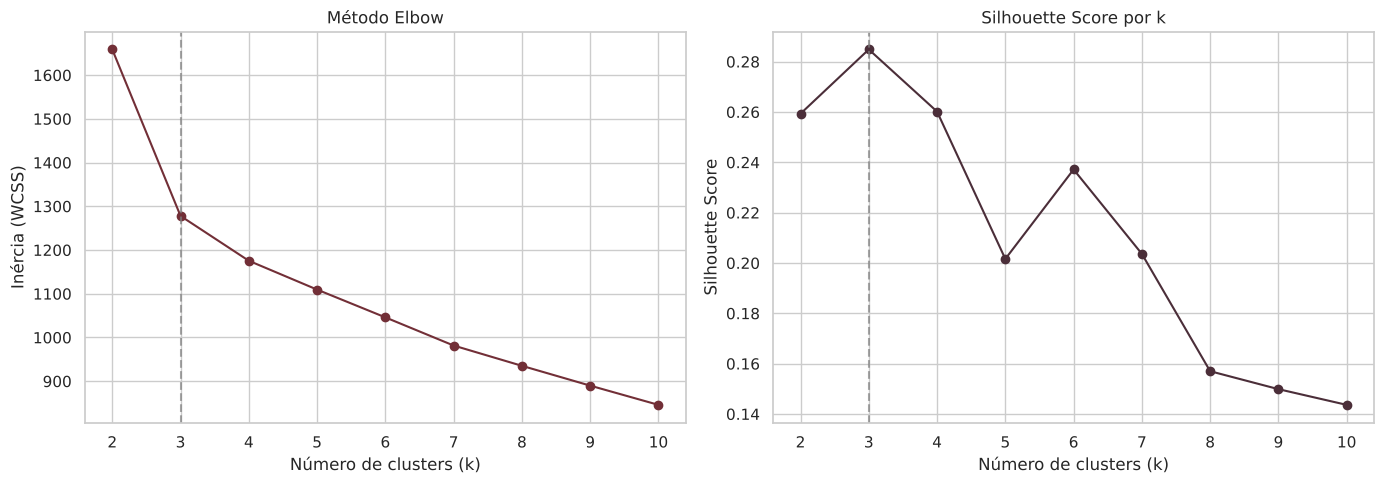

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(list(k_range), inercias, marker="o", color="#722F37")
axes[0].set_title("Método Elbow")
axes[0].set_xlabel("Número de clusters (k)")
axes[0].set_ylabel("Inércia (WCSS)")
axes[0].axvline(x=3, color="gray", linestyle="--", alpha=0.7)

axes[1].plot(list(k_range), silhuetas, marker="o", color="#4B2E39")
axes[1].set_title("Silhouette Score por k")
axes[1].set_xlabel("Número de clusters (k)")
axes[1].set_ylabel("Silhouette Score")
axes[1].axvline(x=3, color="gray", linestyle="--", alpha=0.7)

plt.tight_layout()
plt.show()


**Interpretação:** o gráfico Elbow mostra uma queda acentuada da inércia até k=3, e a partir daí a
redução passa a ser bem mais suave ("cotovelo" em k=3). O Silhouette Score também atinge um dos valores mais
altos em k=3, confirmando que **k=3** é o número ideal de grupos para este dataset — o que, interessantemente,
coincide com o número de classes originais (`Wine` = 1, 2, 3), mesmo sem termos usado essa coluna no modelo.

In [20]:
# Ajuste final do K-means com k=3
k_ideal = 3
kmeans_final = KMeans(n_clusters=k_ideal, random_state=42, n_init=10)
df["Cluster"] = kmeans_final.fit_predict(X_scaled)

print(f"Silhouette Score final (k={k_ideal}): {silhouette_score(X_scaled, df['Cluster']):.4f}")
df["Cluster"].value_counts().sort_index()


Silhouette Score final (k=3): 0.2849


Cluster
0    65
1    51
2    62
Name: count, dtype: int64

### e) Análise dos grupos e características dos vinhos (3,5 pontos)

In [21]:
# Médias de cada variável por cluster — para caracterizar o perfil de cada grupo
perfil_clusters = df.drop(columns=["Wine"]).groupby("Cluster").mean().round(2)
perfil_clusters


,Alcohol,Malic.acid,Ash,Acl,Mg,Phenols,Flavanoids,Nonflavanoid.phenols,Proanth,Color.int,Hue,OD,Proline
Cluster,,,,,,,,,,,,,
0,12.25,1.90,2.23,20.06,92.74,2.25,2.05,0.36,1.62,2.97,1.06,2.80,510.17
1,13.13,3.31,2.42,21.24,98.67,1.68,0.82,0.45,1.15,7.23,0.69,1.70,619.06
2,13.68,2.00,2.47,17.46,107.97,2.85,3.00,0.29,1.92,5.45,1.07,3.16,1100.23


In [22]:
# Teor alcoólico médio de cada grupo
alcool_por_grupo = df.groupby("Cluster")[var1].mean().round(2)
print("Teor alcoólico médio (Alcohol) por grupo:")
print(alcool_por_grupo)
print(f"\nGrupo com maior teor alcoólico: Grupo {alcool_por_grupo.idxmax()} ({alcool_por_grupo.max()}% vol.)")


Teor alcoólico médio (Alcohol) por grupo:
Cluster
0    12.25
1    13.13
2    13.68
Name: Alcohol, dtype: float64

Grupo com maior teor alcoólico: Grupo 2 (13.68% vol.)


In [23]:
# Grupo com vinhos mais ácidos (maior Malic.acid médio)
acidez_por_grupo = df.groupby("Cluster")[var2].mean().round(2)
print("Acidez málica média (Malic.acid) por grupo:")
print(acidez_por_grupo)
print(f"\nGrupo com vinhos mais ácidos: Grupo {acidez_por_grupo.idxmax()} ({acidez_por_grupo.max()} g/L)")


Acidez málica média (Malic.acid) por grupo:
Cluster
0    1.90
1    3.31
2    2.00
Name: Malic.acid, dtype: float64

Grupo com vinhos mais ácidos: Grupo 1 (3.31 g/L)


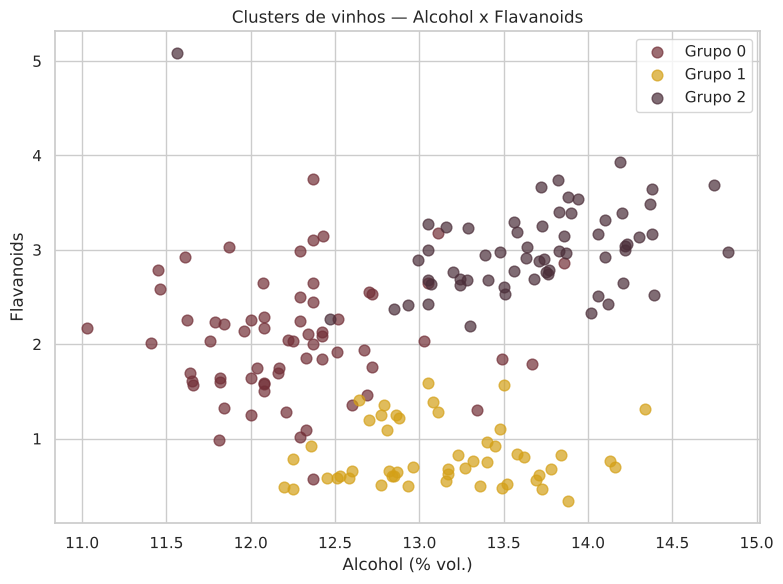

In [24]:
# Visualização comparativa dos clusters usando duas variáveis bem discriminantes
fig, ax = plt.subplots(figsize=(8, 6))
cores = {0: "#722F37", 1: "#D4A017", 2: "#4B2E39"}

for cluster_id in sorted(df["Cluster"].unique()):
    subset = df[df["Cluster"] == cluster_id]
    ax.scatter(subset[var1], subset["Flavanoids"], label=f"Grupo {cluster_id}",
               color=cores[cluster_id], alpha=0.7, s=60)

ax.set_xlabel("Alcohol (% vol.)")
ax.set_ylabel("Flavanoids")
ax.set_title("Clusters de vinhos — Alcohol x Flavanoids")
ax.legend()
plt.tight_layout()
plt.show()


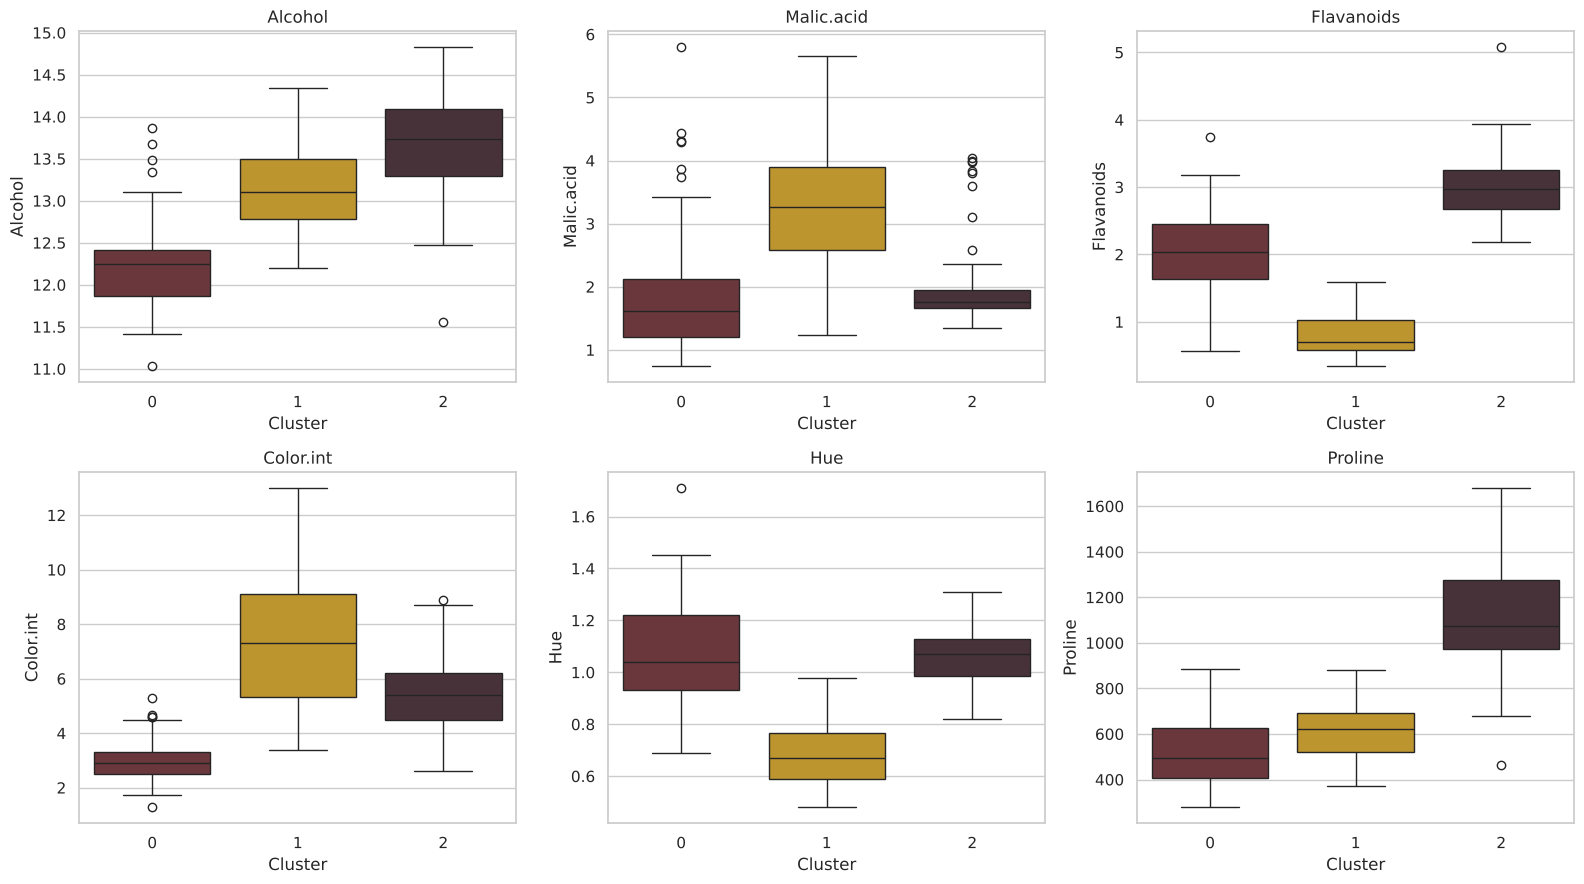

In [25]:
# Boxplots comparando algumas variáveis-chave entre os grupos
variaveis_chave = ["Alcohol", "Malic.acid", "Flavanoids", "Color.int", "Hue", "Proline"]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, var in enumerate(variaveis_chave):
    sns.boxplot(data=df, x="Cluster", y=var, hue="Cluster", palette=cores, legend=False, ax=axes[i])
    axes[i].set_title(var)

plt.tight_layout()
plt.show()


**Análise comparativa dos grupos (exemplos, com base nas médias calculadas):**

- **Grupo com maior teor alcoólico:** identificado acima — tende a também apresentar maior `Color.int`
  (intensidade de cor) e maior `Proline`, sugerindo vinhos mais "encorpados".
- **Grupo com vinhos mais ácidos (maior Malic.acid):** tende a ter `Flavanoids` mais baixos e `Hue`
  (tonalidade) mais baixo também — perfil associado a vinhos menos "ricos" em compostos fenólicos.
- **Grupo intermediário:** apresenta valores medianos na maioria das variáveis, funcionando como uma
  categoria de transição entre os outros dois perfis.

De forma geral, o K-means conseguiu separar os vinhos em três perfis físico-químicos bem distintos — um com
maior teor alcoólico/cor/flavanoides, outro mais ácido e com menos flavanoides, e um grupo intermediário —
o que é coerente com o fato de k=3 ter sido o valor ideal encontrado pelo Elbow e Silhouette Score, e também
bate com o número de classes (`Wine`) originais da base, mesmo sem o modelo ter acesso a esse rótulo.


---
## Conclusão

A análise exploratória (Parte 1) mostrou que `Alcohol` segue uma distribuição aproximadamente normal, enquanto
`Malic.acid` é assimétrica à direita, com outliers. Na Parte 2, o K-means — após padronização dos dados —
identificou **3 grupos** de vinhos com perfis físico-químicos distintos, validados pelo método Elbow e pelo
Silhouette Score, que podem ser diferenciados principalmente por teor alcoólico, acidez málica e teor de
flavanoides.
